# Models supervisats en Pytorch

En xarxes neuronals es poden resoldre els mateixos problemes que en `machine learning`. Es poden arribar a millors resultats en molts casos a costa d'un major cost d'entrenament i d'inferència. A més, necessiten més dades d'entrenament per a obtenir bons resultats. 

Problemes que són massa complexos per a arbres de decisió o models lineals poden ser resolts amb xarxes neuronals. Per exemple, distinguir una persona d'una altra en una foto o traduir textos. 

## Representació de dades en tensors

### Representar dades tabulars

La majoria dels problemes que hem vist a machine learning eren datasets en csv o similars. Les transformacions són les mateixes: One-hot encoding, Label encoding,  normalització o estandarització. 

Però en les dades tabulars en Deep Learning ens podem trobar amb **textos** que no poden organitzar-se en categories. Per convertir els textos en números hem de aplicar tècniques de `NLP`. Transformar els textos a columnes numèriques es diu `embedding` i es fa amb models preentrenats basat en `Recurrent Neural Networks` `RNN`, `LSTM` o `Transformers`.  Ho veurem més endavant. 

### Treballant amb imatges

Una imatge és representada com una col·lecció d'escalars en una quadricula bidimensional amb unes medides concretes. Es poden tenir un o més escalars en cada píxel representant l'escala de grisos, RGB o altres representacions del color. Normalment comptem amb 8 bits per color, encara que algunes imatges mèdiques o industrials poden tenir 10, 12 o 16 bits de profunditat de color. 

És molt fàcil importar una imatge en python:

In [7]:

from PIL import Image
import numpy as np

img = Image.open('perro.jpg')
img_arr = np.array(img)
print(type(img))
print(img_arr.shape)
print(type(img_arr))

<class 'PIL.JpegImagePlugin.JpegImageFile'>
(900, 900, 3)
<class 'numpy.ndarray'>


Pytorch necessita les imatges en un altre layout: Channels, Heigth, Width. L'operació de permutació és molt "barata", ja que no fa copia, juga amb el layout al nivell de tensor. 

In [ ]:
img = torch.from_numpy(img_arr)
out = img.permute(2, 0, 1)

Les xarxes neuronals treballen millor si l'entrada és un número entre 0 i 1, per tant, cal normalitzar els 8 bits (0-255) a eixos valors

In [ ]:
normalized = out.float() / 255.0
mean = out.mean(dim=[1, 2])
std = out.std(dim=[1, 2])
standardized = (normalized - mean[:, None, None]) / std[:, None, None]

## Regressió

Als exemples que s'han vist en l'introducció a Pytorch hen resolt sempre un problema de regressió lineal. Amb xarxes neuronals no hi ha molta diferència entre algorismes, sino en la arquitectura de les capes i les funcions d'activació. D'aquesta manera no es solen fer arbres de decisió o búsqueda de veïns amb xarxes neuronals. Tots els problemes es descomposen en moltes regressions lineals amb distintes funcions d'activació i distinta manera de connectar eixes regressions (perceptrons). 

L'única diferència amb la classificació, per tant, és la funció d'activació final i la funció de pèrdua (loss). En el cas de regressió el més habitual serà fer una capa lineal d'una eixida sense funció d'activació final. 

## Classificació

Fer una classificació en xarxes neuronals implica aplicar una capa d'activació a l'última capa. Si es tracta d'una classificació binària es pot posar una funció sigmoide. En el cas de classificació multiclasse es pot acabar en una capa `lineal` de varies eixides (`logits`) i després fer un `softmax`. 

Anem a veure un exemple de classificació d'imatges simplificat tant en les imatges com en la xarxa proposada. L'interés està més en com organitzar l'entrenament que en el tractament d'imatges. 

Font: https://github.com/dvgodoy/PyTorchStepByStep/blob/master/Chapter04.ipynb 

In [1]:
import random
import numpy as np
from PIL import Image

import torch
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader, Dataset, random_split, WeightedRandomSampler, SubsetRandomSampler
from torchvision.transforms.v2 import Compose, ToTensor, Normalize, ToPILImage, RandomHorizontalFlip, Resize, ToImage, ToDtype

import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')
%matplotlib inline

Utilitzarem una funció externa per generar imatges de dos classes: Diagonals i Horitzontals. Es tracta d'imatges de 5x5. 

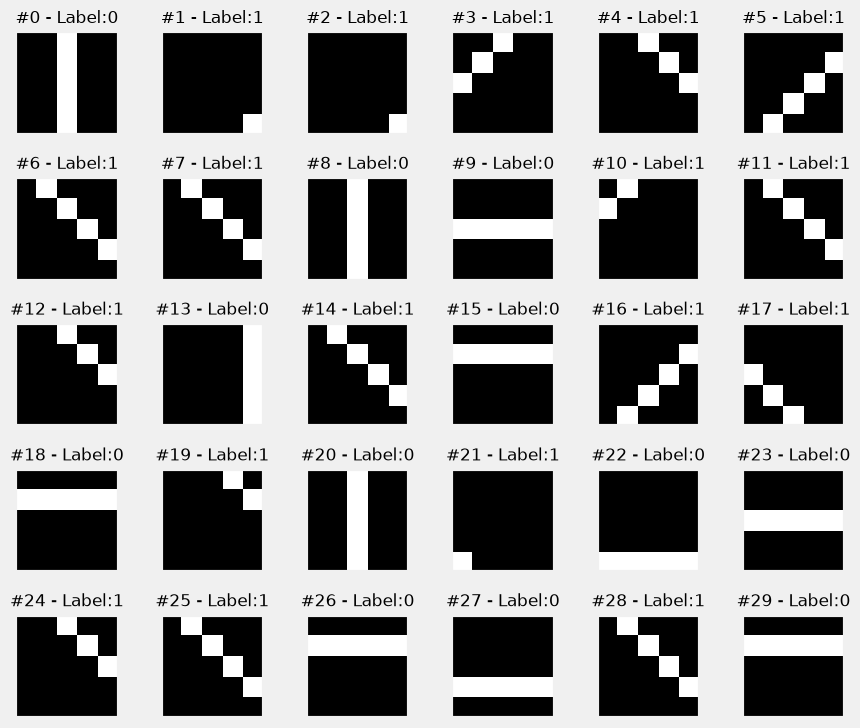

In [8]:
from image_generation import generate_dataset

images, labels = generate_dataset(img_size=5, n_images=300, binary=True, seed=13)

def plot_images(images, targets, n_plot=30):
    n_rows = n_plot // 6 + ((n_plot % 6) > 0)
    fig, axes = plt.subplots(n_rows, 6, figsize=(9, 1.5 * n_rows))
    axes = np.atleast_2d(axes)
    
    for i, (image, target) in enumerate(zip(images[:n_plot], targets[:n_plot])):
        row, col = i // 6, i % 6    
        ax = axes[row, col]
        ax.set_title('#{} - Label:{}'.format(i, target), {'size': 12})
        # plot filter channel in grayscale
        ax.imshow(image.squeeze(), cmap='gray', vmin=0, vmax=1)

    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])
        ax.label_outer()

    plt.tight_layout()
    return fig



fig = plot_images(images, labels, n_plot=30)


In [11]:
images.shape, type(images)

((300, 1, 5, 5), numpy.ndarray)

La forma d'aquest array és adequada a Pytorch amb 300 mostres d'un canal (escala de grisos) de 5x5 pixels. 

Si Observem l'exemple 7 vorem que els píxels blancs tenen valor 255. 

In [10]:
example = images[7]
example

array([[[  0, 255,   0,   0,   0],
        [  0,   0, 255,   0,   0],
        [  0,   0,   0, 255,   0],
        [  0,   0,   0,   0, 255],
        [  0,   0,   0,   0,   0]]], dtype=uint8)

Anem a generar els datasets en tensors i el `DataLoader`:

In [13]:
x_tensor = torch.as_tensor(images / 255).float()
y_tensor = torch.as_tensor(labels.reshape(-1, 1)).float()


class TransformedTensorDataset(Dataset):
    def __init__(self, x, y, transform=None):
        self.x = x
        self.y = y
        self.transform = transform
        
    def __getitem__(self, index):
        x = self.x[index]
        
        if self.transform:
            x = self.transform(x)
        
        return x, self.y[index]
        
    def __len__(self):
        return len(self.x)


composer = Compose([RandomHorizontalFlip(p=0.5),
                    Normalize(mean=(.5,), std=(.5,))])

dataset = TransformedTensorDataset(x_tensor, y_tensor, transform=composer)

Aquesta transformació agafa una imatge i la capgira horitzontalment de manera aleatòria amb una probabilitat del 50% ($p=0.5$). Això vol dir que, per a cada imatge que passa pel conjunt de dades, hi ha un 50% de probabilitats que s'inverteixi i un 50% que es quede tal com estava.

El seu objectiu principal és realitzar augmentació de dades (`data augmentation`), la qual cosa evita el sobreajust (`overfitting`) al retornar imatges diferents però amb el mateix significat i etiqueta cada vegada que es demana durant l'entrenament. Amés, amb més dades, el model generalitzarà millor. 



In [14]:
train_idx, val_idx = random_split(dataset, [0.8, 0.2])

In [16]:
train_sampler = SubsetRandomSampler(train_idx)
val_sampler = SubsetRandomSampler(val_idx)
train_loader = DataLoader(dataset=dataset, batch_size=16, sampler=train_sampler)
val_loader = DataLoader(dataset=dataset, batch_size=16, sampler=val_sampler)
len(iter(train_loader)), len(iter(val_loader))

(15, 4)

## Mètriques i augmentació 

## Segmentation